# Bước 2: Data Collection, Understanding & Preparation
## Kiểm Toán Chất Lượng Dữ Liệu Theo Khung DAMA-DMBOK & Lưu Vết (Audit Trail)
### Phân Tích Hành Vi Mua Hàng Của Khách Hàng Trong Thương Mại Điện Tử (Tập Dữ Liệu Gốc: 500.000 Bản Ghi)
#### Đề án Môn học: Applied Data Analytics (ADY201m) — ĐH FPT
---


## 2.0 Tuyên ngôn Các Nguyên tắc Quản trị Dữ liệu (Data Governance Principles)

Nhằm đảm bảo tính khoa học, minh bạch và khả năng tái lập trong thực tế doanh nghiệp, toàn bộ quy trình tiền xử lý dữ liệu của dự án được xây dựng dựa trên 3 trụ cột cốt lõi:

1. **Khung Đánh Giá Toàn Diện (DAMA-DMBOK 6 Chiều):**
   Đánh giá và kiểm toán chất lượng dữ liệu có hệ thống theo 6 chiều chuẩn mực quốc tế:
   - *Completeness (Đầy đủ):* Không chứa ô trống (Null/NaN) trên toàn bộ 500.000 bản ghi.
   - *Uniqueness (Duy nhất):* Khử trùng lặp (Deduplication), đảm bảo mỗi bản ghi là một phiên tương tác độc nhất.
   - *Validity (Hợp lệ):* Giá trị biến số phải nằm đúng miền logic thực tế (không chấp nhận số âm ở biến đếm hoặc biến thời gian).
   - *Consistency (Nhất quán):* Logic nghiệp vụ giữa các thuộc tính không mâu thuẫn (ví dụ: ngày mua gần nhất không thể lớn hơn thâm niên tài khoản).
   - *Accuracy (Chính xác):* Giữ nguyên độ chính xác số học (Round-trip precision), không làm tròn sai lệch kiểu số.
   - *Timeliness (Kịp thời):* Phản ánh đúng thời điểm phát sinh hành vi, kiểm soát chặt chẽ mốc thời gian để loại bỏ hoàn toàn rủi ro rò rỉ dữ liệu (No Data Leakage).

2. **Kỹ Thuật Lưu Vết Kiểm Toán (Audit Trail & Reproducibility):**
   - *Tính bất biến của dữ liệu gốc:* Tuyệt đối không can thiệp hay ghi đè lên file dữ liệu ban đầu. Kiểm định tính toàn vẹn cấu trúc (500.000 dòng × 17 cột) bằng bảng cờ lỗi `issues` độc lập.
   - *Phân tách có lưu vết:* Tách 100% bản ghi vi phạm (67.744 dòng) sang kho lưu trữ riêng (`customerData_rejected.csv`) theo đúng chỉ số dòng gốc, đảm bảo mọi thao tác đều có thể truy vết và kiểm chứng.

3. **Bảo Toàn Tính Đại Diện & Chân Thực Của Thị Trường:**
   - Phân định rạch ròi giữa **dữ liệu sai hỏng kỹ thuật/logic** (7 vấn đề cần bóc tách) và **biến thiên tự nhiên của khách hàng thật** (như nhóm khách hàng có thu nhập cao hoặc gắn bó lâu năm).
   - Dự án bảo toàn trọn vẹn các quan sát thực tế này, không sử dụng công thức toán cắt gọt cơ học (Trimming hay Winsorization theo IQR) làm méo mó chân dung khách hàng thật.

## 2.1 Import Thư viện & Thiết lập Môi trường Làm việc

**Mục tiêu:** Nạp các thư viện phân tích dữ liệu cốt lõi (`pandas`, `numpy`, `os`) và tự động thiết lập đường dẫn truy xuất tệp dữ liệu, đảm bảo code chạy tương thích và ổn định ở mọi môi trường thực thi.


In [16]:
import os
import pandas as pd
import numpy as np

# Thiết lập đường dẫn dữ liệu tự động (chạy từ thư mục gốc hoặc thư mục Notebooks)
DATA_DIR = '../Data' if os.path.exists('../Data') else 'Data'
RAW_PATH = os.path.join(DATA_DIR, 'customerData_500k.csv')
CLEAN_PATH = os.path.join(DATA_DIR, 'customerData_clean.csv')
REJECTED_PATH = os.path.join(DATA_DIR, 'customerData_rejected.csv')

print(f"Đường dẫn tệp dữ liệu gốc: {RAW_PATH}")


Đường dẫn tệp dữ liệu gốc: ../Data\customerData_500k.csv


## 2.2 Nạp Dữ liệu & Kiểm toán Chất lượng Tổng thể (DAMA-DMBOK Audit)

**Mục tiêu kiểm toán:** Nạp dữ liệu vào DataFrame, xác thực tính toàn vẹn cấu trúc (500.000 dòng × 17 cột), kiểm tra tính Đầy đủ (Completeness) và tính Duy nhất (Uniqueness) theo chuẩn DAMA-DMBOK.


In [17]:
raw = pd.read_csv(RAW_PATH, float_precision='round_trip')
print(f"Kích thước dữ liệu gốc: {raw.shape[0]:,} dòng × {raw.shape[1]} cột\nTrùng lặp: {raw.duplicated().sum():,} dòng\nKhuyết thiếu: {raw.isna().any().sum():,} dòng")
raw.dtypes.to_frame('Kiểu dữ liệu')

Kích thước dữ liệu gốc: 500,000 dòng × 17 cột
Trùng lặp: 0 dòng
Khuyết thiếu: 0 dòng


,Kiểu dữ liệu
Age,int64
AnnualIncome,float64
NumberOfPurchases,int64
TimeSpentOnWebsite,float64
CustomerTenureYears,float64
LastPurchaseDaysAgo,int64
Gender,str
ProductCategory,str
PreferredDevice,str
Region,str


## 2.2.1 Thăm Dò Phân Phối Bằng Boxplot & Đánh Giá Giới Hạn Của Phương Pháp IQR

* **Mục tiêu:** Thăm dò hình dạng phân phối của 6 biến số định lượng quan trọng và kiểm tra tính khả thi của phương pháp phát hiện ngoại lai truyền thống theo chuẩn $1.5 \times \text{IQR}$.
* **Công thức thống kê:** Ngưỡng dưới = $Q1 - 1.5 \times \text{IQR}$; Ngưỡng trên = $Q3 + 1.5 \times \text{IQR}$.

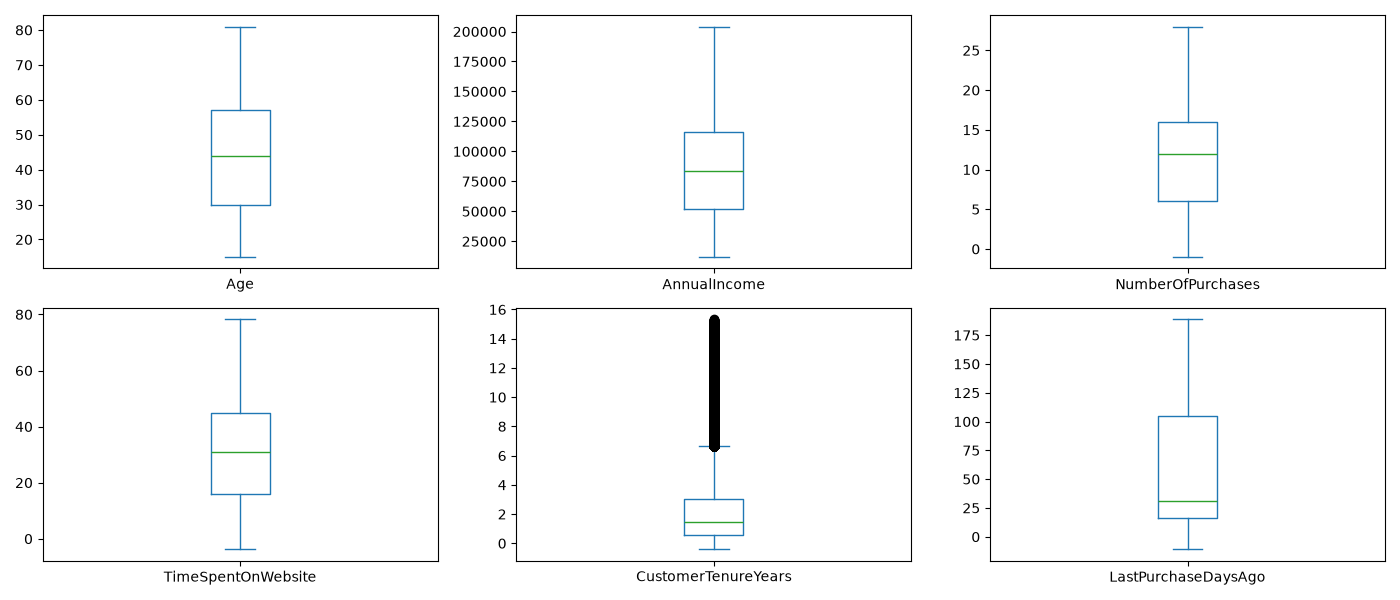

,Ngưỡng dưới,Ngưỡng trên,Số dòng ngoài ngưỡng,Tỷ lệ (%)
Age,-10.50,97.50,0,0.0%
AnnualIncome,-44835.00,213388.51,0,0.0%
NumberOfPurchases,-9.00,31.00,0,0.0%
TimeSpentOnWebsite,-27.91,88.77,0,0.0%
CustomerTenureYears,-3.03,6.64,24803,4.96%
LastPurchaseDaysAgo,-117.50,238.50,0,0.0%


In [3]:
# 1. Vẽ Boxplot 6 biến số định lượng
cols = ['Age', 'AnnualIncome', 'NumberOfPurchases', 'TimeSpentOnWebsite', 'CustomerTenureYears', 'LastPurchaseDaysAgo']
raw[cols].plot(kind='box', subplots=True, layout=(2, 3), figsize=(14, 6))
plt.tight_layout()
plt.show()

# 2. Tính ngưỡng ngoại lai theo IQR và đếm số dòng vi phạm
q1, q3 = raw[cols].quantile(0.25), raw[cols].quantile(0.75)
lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
outliers = (raw[cols] < lower) | (raw[cols] > upper)

pd.DataFrame({
    'Ngưỡng dưới': lower.round(2),
    'Ngưỡng trên': upper.round(2),
    'Số dòng ngoài ngưỡng': outliers.sum(),
    'Tỷ lệ (%)': (outliers.mean() * 100).round(2).astype(str) + '%'
})

> **Kết luận kiểm toán: Cơ sở khoa học bác bỏ phương pháp lọc theo IQR thuần túy**
>
> Bảng tính toán định lượng trên chứng minh phương pháp $1.5 \times \text{IQR}$ bộc lộ **2 hạn chế nghiêm trọng** khi áp dụng vào dữ liệu thương mại điện tử:
> 1. **Bỏ lọt lỗi hệ thống (False Negative):** Do dữ liệu phân phối trải rộng, ngưỡng dưới của hầu hết các biến đều bị âm sâu ($-9.0$ lần mua, $-27.91$ phút, $-117.5$ ngày). Phương pháp IQR hoàn toàn **bỏ sót toàn bộ các bản ghi lỗi hệ thống có giá trị âm** (`-1` lần mua, thời gian âm do lệch clock log) vì coi các giá trị này vẫn "nằm trong ngưỡng hợp lệ".
> 2. **Triệt tiêu tệp khách hàng giá trị cao (False Positive):** Ở biến thâm niên `CustomerTenureYears`, ngưỡng trên là $6.64$ năm. Nếu máy móc cắt bỏ (Trimming) hay ép trần (Capping), hệ thống sẽ **loại bỏ oan 24.803 khách hàng trung thành nhất** (chiếm 4.96% toàn sàn) — vốn là tệp người dùng mang lại giá trị vòng đời (LTV) cao nhất cho doanh nghiệp.
>
> 👉 **KẾT LUẬN & ĐỊNH HƯỚNG:** Phương pháp thống kê IQR thuần túy không phản ánh đúng bản chất hành vi tiêu dùng và không phát hiện được mâu thuẫn đa biến. Đây là cơ sở thực nghiệm vững chắc để dự án xây dựng **Khung 7 vấn đề kiểm toán logic nghiệp vụ (Audit Trail)** tại Mục 2.3 dưới đây.

## 2.3 Thiết Lập Bảng Lưu Vết Kiểm Toán (Audit Trail) Cho 7 Vấn Đề Nghiệp Vụ

Tuân thủ nguyên tắc quản trị dữ liệu, quy trình làm sạch **không xóa trực tiếp dữ liệu thô** mà sử dụng cơ chế **Lưu vết kiểm toán (Audit Trail)**. Bảng `issues` được khởi tạo song song với 500.000 bản ghi gốc để ghi nhận độc lập các cờ vi phạm (flags) qua 7 quy tắc nghiệp vụ, giúp việc phân tách dữ liệu minh bạch và truy xuất được nguồn gốc lỗi.

In [18]:
# Khởi tạo bảng lưu vết kiểm toán lỗi cho 500.000 bản ghi gốc
issues = pd.DataFrame(index=raw.index)

### 2.3.1 Vấn đề 1: Sai miền giá trị (Số âm đơn biến)

* **Vấn đề:** 4 cột gồm số lần mua (`NumberOfPurchases`) và các cột thời gian (`TimeSpentOnWebsite`, `CustomerTenureYears`, `LastPurchaseDaysAgo`) bị dính giá trị âm. Thực tế kiểm tra cho thấy số lần mua âm toàn là `-1` (mã lỗi của hệ thống), còn thời gian âm là do lệch đồng hồ khi ghi log.
* **Cân nhắc:** Không thể dùng `abs()` để đổi dấu vì `-1` không phải là khách mua 1 lần. Cũng không tự ý điền trung bình hay trung vị vì sẽ làm sai lệch dữ liệu thật của khách hàng.
* **Quyết định:** Loại bỏ **27.435 dòng này (5,49%)** và chuyển sang bảng `rejected` để lưu lại lý do.

In [19]:
# Vấn đề 1: Đánh dấu các bản ghi có giá trị âm ở 4 biến định lượng
issues['neg_values'] = (
    (raw['NumberOfPurchases'] < 0) |
    (raw['TimeSpentOnWebsite'] < 0) |
    (raw['CustomerTenureYears'] < 0) |
    (raw['LastPurchaseDaysAgo'] < 0)
)

### 2.3.2 Vấn đề 2: Nghịch lý thời gian — Mua hàng trước khi tạo tài khoản

* **Vấn đề:** Điều kiện `LastPurchaseDaysAgo > CustomerTenureYears * 365.25`. Kiểm tra cho thấy 100% các dòng này đều rơi vào tài khoản mới (< 6 tháng), điển hình có khách tạo nick 6 ngày nhưng ghi nhận 18 đơn mua từ 181 ngày trước. Lỗi phát sinh do gộp lịch sử mua của khách vãng lai hoặc reset ngày tạo nick khi chuyển đổi hệ thống.
* **Tác động:** Làm sai lệch trực tiếp:
  - *Ma trận RFM (Notebook 4 & 5):* Recency bị tính sai, làm biến dạng biểu đồ Heatmap phân nhóm khách hàng.
  - *Phân khúc VIP/Premium (Notebook 3 & 5):* Khách mới bị đội lốt khách mua nhiều đơn, làm sai lệch các truy vấn SQL và phân tích so sánh phân khúc.
  - *Mô hình dự đoán `PurchaseStatus` (Notebook 6):* Mâu thuẫn mốc thời gian khiến thuật toán học máy học sai quy luật hành vi.
* **Quyết định:** Loại bỏ toàn bộ **40.666 dòng này (chiếm 8,13%)** và đưa vào bảng `rejected` để bảo vệ độ chính xác cho các bước phân tích phía sau.

In [20]:
# Vấn đề 2: Mua hàng trước ngày tạo tài khoản
issues['purchase_before_tenure'] = raw['LastPurchaseDaysAgo'] > (raw['CustomerTenureYears'] * 365.25)

### 2.3.3 Vấn đề 3: Mâu thuẫn giao dịch — Chưa mua hàng nhưng có ngày mua gần nhất

* **Bản chất mâu thuẫn:** Điều kiện lọc là `NumberOfPurchases == 0` nhưng `LastPurchaseDaysAgo > 0` (phát hiện 8.125 dòng, chiếm 1,63%). Khi ghép với biến mục tiêu `PurchaseStatus`, dữ liệu bộc lộ 2 nghịch lý cụ thể:
  - *Khi khách chốt đơn trong phiên (`PurchaseStatus = 1` — 2.749 dòng):* Vì lịch sử ghi `NumberOfPurchases = 0` (chưa từng mua gì), nên đơn hàng khách bấm mua hôm nay chính là **đơn hàng đầu tiên trong đời**. Thế nhưng cột `LastPurchaseDaysAgo` lại ghi nhận khách đã có lần mua cách đây 61 ngày (`> 0`). **Nghịch lý:** Một người đang mua đơn hàng đầu tiên thì không thể có "ngày mua gần nhất từ 2 tháng trước".
  - *Khi khách không mua trong phiên (`PurchaseStatus = 0` — 5.376 dòng):* Quá khứ chưa từng mua (`NumberOfPurchases = 0`), phiên này cũng không mua (`PurchaseStatus = 0`), nghĩa là tài khoản này **chưa bao giờ phát sinh bất kỳ đơn hàng nào**. Vậy con số `LastPurchaseDaysAgo > 0` (lần mua gần nhất) từ đâu ra? Một người chưa từng mua hàng thì mốc thời gian "cách lần mua gần nhất bao nhiêu ngày" là hoàn toàn vô căn cứ.
* **Bối cảnh hồ sơ & Hậu quả lên mô hình:** Nhóm này đã mở tài khoản trung bình hơn 2 năm, đã tiêu 3 mã giảm giá, và 77% được gắn mác VIP/Premium. Sự mâu thuẫn này làm mô hình học máy (Notebook 6) bị nhiễu loạn nghiêm trọng: thuật toán không thể phân biệt được đâu là hành vi chốt đơn của **khách mới mua lần đầu** và đâu là của **khách VIP mua lặp lại**.
* **Quyết định:** Không thể xác định cột nào ghi nhận đúng để sửa. Biện pháp an toàn nhất là loại bỏ toàn bộ **8.125 dòng này (chiếm 1,63%)** và đưa vào bảng `rejected`.

In [21]:
# Vấn đề 3: Chưa mua hàng nhưng có ngày mua gần nhất
issues['zero_purchases_has_last_date'] = (raw['NumberOfPurchases'] == 0) & (raw['LastPurchaseDaysAgo'] > 0)

### 2.3.4 Vấn đề 4: Mâu thuẫn khuyến mãi — Chưa mua hàng nhưng đã tiêu dùng mã giảm giá

* **Bản chất mâu thuẫn:** Điều kiện lọc là `NumberOfPurchases == 0` nhưng `DiscountsAvailed > 0` (phát hiện 7.534 dòng, chiếm 1,51%). Trong thực tế thương mại điện tử, một đơn hàng có thể gộp (stack) nhiều mã giảm giá (mã sàn, mã shop, freeship). Tuy nhiên, khi bóc tách chi tiết 7.534 dòng này theo trạng thái mua hàng (`PurchaseStatus`) và ngày mua gần nhất (`LastPurchaseDaysAgo`), dữ liệu phân hóa thành 3 nhóm mâu thuẫn rõ rệt:
  - *Nhóm 1 — Hoàn toàn không có đơn hàng nào để áp mã (4.836 dòng — 64,2%):* Khách có `PurchaseStatus = 0` (phiên này không mua) và `NumberOfPurchases = 0` (quá khứ chưa từng mua). Khách hàng không hề phát sinh bất kỳ đơn hàng nào nhưng hệ thống vẫn ghi nhận đã tiêu dùng từ 1 đến 10 voucher vào không khí.
  - *Nhóm 2 — Chốt đơn hôm nay nhưng mâu thuẫn lịch sử mua cũ (2.638 dòng — 35,0%):* Khách có `PurchaseStatus = 1`, nhưng `LastPurchaseDaysAgo` lại ghi nhận lần mua gần nhất từ 60 – 180 ngày trước. Nếu khách đã từng mua và áp mã từ nhiều tháng trước, tại sao bộ đếm `NumberOfPurchases` lại không ghi nhận đơn hàng đó mà vẫn để bằng 0?
  - *Nhóm 3 — Khách mua hôm nay và áp nhiều mã tân thủ (60 dòng — 0,8%):* Nhóm duy nhất thỏa mãn kịch bản mua đơn đầu tiên hôm nay (`PurchaseStatus = 1` và `LastPurchaseDaysAgo = 0`). Tuy nhiên, ngay cả ở 60 dòng này, có tới 80% khách hàng đã mang cấp bậc VIP/Premium với thâm niên trung bình gần 2 năm — một nghịch lý lớn vì không hệ thống nào phong VIP cho tài khoản 2 năm chưa từng phát sinh đơn hàng.
* **Hậu quả lên bài toán kinh doanh (RQ3 - Notebook 1 & Mô hình Notebook 6):** Biến `DiscountsAvailed` là thước đo quan trọng để đánh giá hiệu quả khuyến mãi và độ nhạy cảm giá. Dữ liệu mâu thuẫn này làm sai lệch tỷ lệ chuyển đổi thực tế, khiến thuật toán học máy học ra kết luận sai lầm: cấp càng nhiều voucher thì khách càng không có đơn hàng.
* **Quyết định:** Không thể tự đoán số đơn hàng để sửa và cũng không thể gán số voucher về 0. Biện pháp an toàn nhất là loại bỏ toàn bộ **7.534 dòng này (chiếm 1,51%)** sang bảng `rejected`.

In [22]:
# Vấn đề 4: Chưa mua hàng nhưng có lượt áp dụng mã giảm giá
issues['zero_purchases_used_discounts'] = (raw['NumberOfPurchases'] == 0) & (raw['DiscountsAvailed'] > 0)

### 2.3.5 Vấn đề 5: Mâu thuẫn phân khúc — Chưa từng mua hàng nhưng xếp hạng VIP/Premium

* **Bản chất mâu thuẫn & Số liệu thực tế:** Điều kiện `NumberOfPurchases == 0` nhưng `CustomerSegment` thuộc nhóm `['VIP', 'Premium']` (phát hiện 6.426 dòng, chiếm 1,29%, gồm 3.946 khách Premium và 2.480 khách VIP). Trong nghiệp vụ bán lẻ, phân hạng VIP và Premium bắt buộc phải tích lũy từ lịch sử mua sắm và chi tiêu thực tế. Một tài khoản chưa từng hoàn tất bất kỳ giao dịch nào không thể được thăng hạng lên phân khúc khách hàng giá trị cao nhất.
* **Tác động lên phân tích (Notebook 3, 5 và 6):**
  - *Phân tích SQL & Trực quan hóa:* Các thống kê so sánh giữa các phân khúc (`CustomerSegment`) bị méo mó khi nhóm VIP/Premium bị gánh thêm hơn 6.400 tài khoản ảo mang số đơn bằng 0.
  - *Mô hình dự báo (`PurchaseStatus`):* Đặc trưng `Segment_VIP` bị nhiễu loạn, làm thuật toán học máy hiểu sai hành vi chuyển đổi của nhóm khách hàng cao cấp thực thụ.
* **Cân nhắc & Quyết định:** Không thể tự ý giáng hạng khách về `Regular` vì đây có thể là các tài khoản thử nghiệm (test accounts) của kỹ thuật viên. Biện pháp chuẩn mực là loại bỏ toàn bộ **6.426 dòng này (chiếm 1,29%)** sang bảng `rejected`.

In [23]:
# Vấn đề 5: Chưa mua hàng nhưng xếp hạng VIP/Premium
issues['zero_purchases_vip_segment'] = (raw['NumberOfPurchases'] == 0) & (raw['CustomerSegment'].isin(['VIP', 'Premium']))

### 2.3.6 Vấn đề 6: Vi phạm quy định pháp lý — Tuổi tạo tài khoản dưới 13 tuổi (COPPA/GDPR)

* **Bản chất mâu thuẫn & Thực tế dữ liệu:** Điều kiện `(Age - CustomerTenureYears) < 13` (phát hiện 3.925 dòng, chiếm 0,79%). Khi lấy tuổi hiện tại trừ đi thâm niên, độ tuổi lúc mở nick của nhóm này chỉ từ 1,9 đến dưới 13 tuổi (trung bình là 10,9 tuổi). Điển hình có trường hợp khách 18 tuổi nhưng thâm niên 8,5 năm (tạo nick lúc 9 tuổi). Đây là lỗi sinh dữ liệu giả lập (synthetic data) khi ghép ngẫu nhiên độ tuổi thanh thiếu niên với số năm thâm niên quá lớn.
* **Khía cạnh pháp lý & Tác động lên phân tích (RQ1 - Notebook 1):**
  - *Quy chuẩn pháp lý & Điều khoản sàn:* Theo Đạo luật COPPA, GDPR và điều khoản dịch vụ TMĐT, trẻ em dưới 13 tuổi không được phép tự mở tài khoản và giao dịch độc lập.
  - *Nhiễu loạn phân tích nhân khẩu học:* Nhóm khách trẻ (`Young < 30`) ở mục 2.7 và câu hỏi nghiên cứu RQ1 sẽ bị sai lệch khi chứa các hồ sơ phi thực tế (trẻ em 8 – 10 tuổi mua sắm với thu nhập hàng trăm nghìn USD).
* **Quyết định:** Không thể tự ý tăng tuổi hay cắt bớt thâm niên. Biện pháp chuẩn mực là loại bỏ toàn bộ **3.925 dòng này (chiếm 0,79%)** sang bảng `rejected`.

In [24]:
# Vấn đề 6: Độ tuổi khi tạo tài khoản dưới 13 tuổi
issues['underage_account_creation'] = (raw['Age'] - raw['CustomerTenureYears']) < 13

### 2.3.7 Vấn đề 7: Hành vi nghi vấn Bot / Spam đánh giá cực đoan

* **Bản chất mâu thuẫn & Thực tế dữ liệu:** Điều kiện `TimeSpentOnWebsite < 1` và `PurchaseStatus == 0` và `CustomerSatisfaction in [1, 5]` (phát hiện 601 dòng, chiếm 0,12%, gồm 447 lượt chấm 5 sao và 154 lượt chấm 1 sao). Khách truy cập web chưa đầy 1 phút (nhiều phiên chỉ vài giây), hoàn toàn không phát sinh giao dịch, nhưng lại lập tức đánh giá trải nghiệm ở hai thái cực cảm xúc tuyệt đối.
* **Chứng minh tại sao chỉ lọc 1 và 5 sao (Hiện tượng Bimodal Extreme Polarity):**
  - *Tại sao không lọc 2, 3, 4 sao:* Có hơn 10.000 khách vào dưới 1 phút chấm 2, 3, 4 sao. Đây là hành vi tự nhiên của người thật khi lướt dạo không ưng ý bấm thoát (Bounce Rate) và chọn điểm trung tính/vừa phải để tắt khảo sát. Nếu lọc cả nhóm này sẽ xóa oan khách hàng thật.
  - *Sự phi lý của 1 và 5 sao:* Một người chưa mua món nào, vào web vài chục giây thì không thể có trải nghiệm hoàn hảo để chấm 5 sao (dấu hiệu của Bot seeding tạo uy tín ảo), và cũng chưa thể có trải nghiệm tồi tệ để căm phẫn chấm 1 sao (dấu hiệu của Review Bombing phá hoại hoặc lỗi văng app). Bot chạy kịch bản tự động chỉ nhắm vào 2 cực để tâng bốc hoặc dìm hàng tối đa.
* **Quyết định:** Loại bỏ chuẩn xác **601 dòng này (chiếm 0,12%)** sang bảng `rejected`, bảo vệ biến `CustomerSatisfaction` khỏi tín hiệu giả và giữ lại toàn vẹn nhóm người thật lướt dạo.

In [25]:
# Vấn đề 7: Nghi vấn Bot/Spam đánh giá cực đoan không mua hàng
issues['bot_extreme_review'] = (raw['TimeSpentOnWebsite'] < 1) & (raw['PurchaseStatus'] == 0) & (raw['CustomerSatisfaction'].isin([1, 5]))

## 2.4 Tổng Hợp Bóc Tách Dữ Liệu Sạch (Clean) & Dữ Liệu Từ Chối (Rejected)

Sau khi kiểm toán độc lập qua 7 vấn đề nghiệp vụ, tiến hành hợp nhất toàn bộ các dòng vi phạm (phép toán `OR` logic) để phân tách bộ dữ liệu thành 2 tập riêng biệt:
- **Tập Hợp Lệ (Clean):** Giữ lại các bản ghi nhất quán để phục vụ phân tích mô tả, RFM, SQL và huấn luyện mô hình Machine Learning.
- **Tập Từ Chối (Rejected):** Lưu trữ toàn bộ các bản ghi vi phạm kèm lưu vết kiểm toán (Audit Trail) để đội ngũ kỹ thuật hệ thống rà soát lỗi backend.

In [26]:
# Hợp nhất các cờ lỗi (phép OR logic) và phân tách 2 tập dữ liệu
rejected_mask = issues.any(axis=1)
clean = raw[~rejected_mask].copy()
rejected = raw[rejected_mask].copy()

# Tổng hợp nhanh số dòng vi phạm của 7 vấn đề
summary = issues.sum().rename({
    'neg_values': '1. Sai miền giá trị (Số âm)',
    'purchase_before_tenure': '2. Mua hàng trước khi tạo nick',
    'zero_purchases_has_last_date': '3. Chưa mua nhưng có ngày mua',
    'zero_purchases_used_discounts': '4. Chưa mua nhưng dùng voucher',
    'zero_purchases_vip_segment': '5. Chưa mua nhưng là VIP/Premium',
    'underage_account_creation': '6. Tuổi mở nick < 13 tuổi',
    'bot_extreme_review': '7. Bot/Spam đánh giá cực đoan'
}).to_frame('Số dòng')

summary.loc['TỔNG LỖI (Hợp nhất OR)'] = rejected_mask.sum()
summary.loc['DỮ LIỆU SẠCH (Hợp lệ)'] = len(clean)
summary['Tỷ lệ (%)'] = (summary['Số dòng'] / len(raw) * 100).round(2)
summary

## 2.4.1 Chuẩn Hóa Dữ Liệu Số & Định Dạng Thời Gian Trực Quan (Phút - Giây, Năm - Tháng)

* **Làm tròn tiền tệ & thời gian:** Làm tròn 2 số thập phân cho `AnnualIncome`, `TimeSpentOnWebsite`, `CustomerTenureYears`.
* **Trực quan hóa thời gian:** Bổ sung 2 cột đọc hiểu `TimeSpent_Formatted` (Phút & Giây) và `Tenure_Formatted` (Năm & Tháng) phục vụ hiển thị báo cáo.
* **Bảo toàn tính toán:** Giữ nguyên các trường định lượng gốc dạng số thực để cung cấp cho SQL (Notebook 3) và Machine Learning (Notebook 6).

In [13]:
# 1. Làm tròn 2 số thập phân cho các biến số thực
clean[['AnnualIncome', 'TimeSpentOnWebsite', 'CustomerTenureYears']] = clean[['AnnualIncome', 'TimeSpentOnWebsite', 'CustomerTenureYears']].round(2)

# 2. Tạo 2 cột thời gian trực quan dễ đọc (Phút - Giây, Năm - Tháng)
clean['TimeSpent_Formatted'] = clean['TimeSpentOnWebsite'].apply(lambda x: f"{int(x)} phút {int(round((x % 1) * 60)):02d} giây")
clean['Tenure_Formatted'] = clean['CustomerTenureYears'].apply(lambda x: f"{int(x)} năm {int(round((x % 1) * 12))} tháng" if int(x) > 0 else f"{int(round(x * 12))} tháng")

# 3. Hiển thị kiểm tra 5 dòng đầu
display(clean[['AnnualIncome', 'TimeSpentOnWebsite', 'TimeSpent_Formatted', 'CustomerTenureYears', 'Tenure_Formatted']].head())

,AnnualIncome,TimeSpentOnWebsite,TimeSpent_Formatted,CustomerTenureYears,Tenure_Formatted
0,57722.57,5.91,5 phút 55 giây,1.09,1 năm 1 tháng
1,21328.93,6.97,6 phút 58 giây,0.65,8 tháng
2,150537.74,35.00,35 phút 00 giây,3.86,3 năm 10 tháng
5,25950.81,54.26,54 phút 16 giây,4.91,4 năm 11 tháng
7,51222.01,57.51,57 phút 31 giây,1.01,1 năm 0 tháng


## 2.5 Xuất Tệp Dữ Liệu Sạch & Lưu Tệp Kiểm Toán

**Hành động:** Lưu các tệp dữ liệu đã làm sạch (bảo toàn 17 thuộc tính nghiệp vụ gốc) ra file CSV phục vụ cho các bước phân tích tiếp theo.

In [28]:
# Xuất file dữ liệu sạch và dữ liệu lỗi (17 cột gốc)
clean.to_csv(CLEAN_PATH, index=False, encoding='utf-8-sig')
rejected.to_csv(REJECTED_PATH, index=False, encoding='utf-8-sig')
print(f"Đã lưu: {len(clean):,} dòng sạch ({clean.shape[1]} cột) và {len(rejected):,} dòng lỗi ({rejected.shape[1]} cột).")

Đã lưu: 432,256 dòng sạch (17 cột) và 67,744 dòng lỗi (17 cột).


---
*Notebook tiếp theo: [3. Data Analysis with SQL](./3.%20Data%20Analysis%20with%20SQL.ipynb)*
